In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [3]:
# Set random seeds for reproducibility
torch.manual_seed(42)

In [4]:
# Check for GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [7]:
import kagglehub

# Set your custom dataset folder path
custom_path = "./data"
# Download the dataset into your custom folder
path = kagglehub.dataset_download(
    "zalando-research/fashionmnist",
    output_dir=custom_path
)

print("Path to dataset files:", path)

100%|██████████| 68.8M/68.8M [00:14<00:00, 4.96MB/s]

Extracting files...


Path to dataset files: ./data


In [8]:
df = pd.read_csv('./data/fashion-mnist_train.csv')
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
df.shape

(60000, 785)

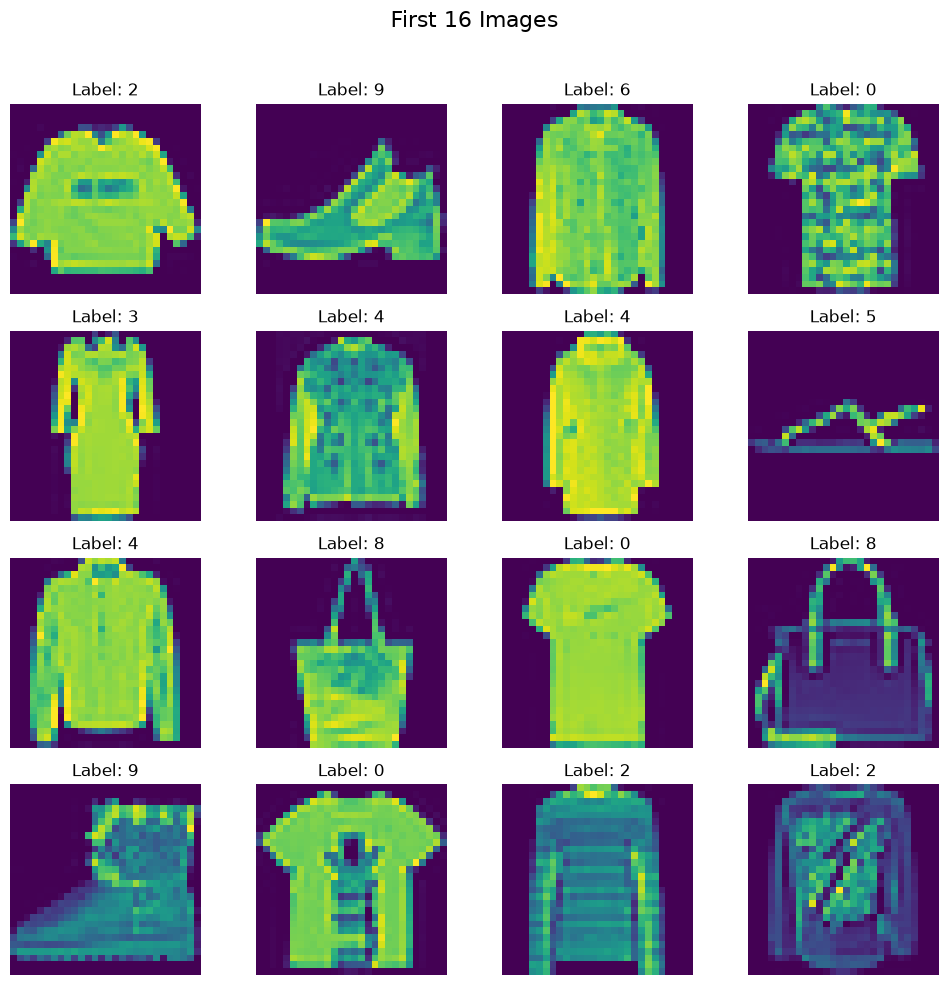

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

# Plot the first 16 images from the dataset
for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(img)  # Display in grayscale
    ax.axis('off')  # Remove axis for a cleaner look
    ax.set_title(f"Label: {df.iloc[i, 0]}")  # Show the label

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit the title
plt.show()

In [11]:
# train test split

X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
X_train = X_train/255.0
X_test = X_test/255.0

In [21]:
class CustomDataset(Dataset):

  def __init__(self,features,labels):
    self.features=torch.tensor(features,dtype=torch.float32).reshape(-1,1,28,28)
    self.labels=torch.tensor(labels,dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self,index):
    return self.features[index],self.labels[index]
  

In [15]:
train_dataset = CustomDataset(X_train, y_train)

In [16]:
test_dataset = CustomDataset(X_test, y_test)

In [19]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True,pin_memory=True)
test_loader=DataLoader(test_dataset,batch_size=32,shuffle=True,pin_memory=True)

In [22]:
class MyNN(nn.Module):

  def __init__(self, input_features):

    super().__init__()

    self.features=nn.Sequential(
      nn.Conv2d(input_features,32,kernel_size=3,padding='same'),
      nn.ReLU(),
      nn.BatchNorm2d(32),
      nn.MaxPool2d(kernel_size=2,stride=2),

      nn.Conv2d(32,64,kernel_size=3,padding='same'),
      nn.ReLU(),
      nn.BatchNorm2d(64),
      nn.MaxPool2d(kernel_size=2,stride=2)
    )
    self.classifier=nn.Sequential(
      nn.Flatten(),
      nn.Linear(64*7*7,128),
      nn.ReLU(),
      nn.Dropout(p=0.3),

      nn.Flatten(),
      nn.Linear(128,64),
      nn.ReLU(),

      nn.Linear(64,10)

    )

  def forward(self,x):
    x=self.features(x)
    x=self.classifier()

    return x

In [ ]:
learning_rate=0.01
epochs=50

1500

In [ ]:
def objective(trial):

    num_hidden_layers=trial.suggest_int('num_hidden_layers',1,5)
    neurons_per_year=trial.suggest_int('neuron_per_layers',8,128,step=8)

    input_dim=784
    output_dim=10

    model= MyNN(input_dim,output_dim,num_hidden_layers,neurons_per_year)
    model.to(device)

    learning_rate=0.01
    epochs=100

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.1, weight_decay=1e-4)

    for epoch in range(epochs):

     for batch_features, batch_labels in train_loader:

      # move data to gpu
      batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

      # forward pass
      outputs = model(batch_features)

      # calculate loss
      loss = criterion(outputs, batch_labels)

      # back pass
      optimizer.zero_grad()
      loss.backward()

      # update grads
      optimizer.step()


In [ ]:
!pip install optuna
import optuna

